## Experiments

In [1]:
pdf_file = r"C:\Users\KULPREET SEMBHI\OneDrive\Desktop\pw projects\RAG\RAG\2027-volvo-xc90.pdf"

In [2]:

!pip install PyPDF2

from pathlib import Path
from PyPDF2 import PdfReader

pdf_path = Path(pdf_file)  # replace with your PDF file path
reader = PdfReader(pdf_path)

text = "\n\n".join(page.extract_text() or "" for page in reader.pages)

txt_path = pdf_path.with_suffix(".txt")
txt_path.write_text(text, encoding="utf-8")

print(f"Saved text to: {txt_path}")


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Saved text to: C:\Users\KULPREET SEMBHI\OneDrive\Desktop\pw projects\RAG\RAG\2027-volvo-xc90.txt


In [3]:
len(text)

755835

In [4]:
import time, textwrap, json, re


import ollama


# ── Reusable helper ───────────────────────────────────────────────────
def call_llm(prompt: str,*,temperature: float = 0.7,max_output_tokens: int = 512,retries: int = 3,) -> str:

    for attempt in range(retries):
        try:
            response = ollama.chat(
                model="llama3.2",
                messages=[{"role": "user", "content": prompt}],
                options={"temperature": temperature, "max_output_tokens": max_output_tokens},
            )
            return response["message"]["content"]
        except Exception as e:
            if attempt < retries - 1:
                wait = 2 ** attempt   # 1s → 2s → 4s
                print(f"[retry {attempt+1}] {e} — waiting {wait}s")
                time.sleep(wait)
            else:
                raise


In [8]:
call_llm(f""" Given here is the document {text} , please answer the following user question based on the document:
         How to mount child seat to the car?""")

"Unfortunately, this document does not provide specific instructions on how to mount a child seat to the car. However, it does provide general information and guidelines for installing child seats in the car.\n\nAccording to the document, it is recommended to:\n\n* Always read the owner's manual section on installing a child seat before installing one in the car.\n* Retract the seat cushion extension before installing a child seat.\n* Use a rear-facing child seat until the child reaches 4 years of age, or until a higher age limit is reached.\n* Choose a child seat that is approved for use in the mass group specified for your child's age and weight.\n* Follow the manufacturer's instructions for installing the child seat, and ensure that it is securely fastened to the car.\n\nAdditionally, the document provides tables and guidelines for locating child seats in the car, as well as warnings and precautions for using child seats.\n\nIt is recommended to consult the owner's manual and follow

In [9]:
# llama2 model has been tried here, we need to install it as well in the list of ollama then we can use this code
import time, textwrap, json, re
import ollama
# ── Reusable helper ───────────────────────────────────────────────────
def call_llm(prompt: str,*,temperature: float = 0.7,max_output_tokens: int = 512,retries: int = 3,) -> str:
    for attempt in range(retries):
        try:
            response = ollama.chat(
                model="llama2",
                messages=[{"role": "user", "content": prompt}],
                options={"temperature": temperature, "max_output_tokens": max_output_tokens},
            )
            return response["message"]["content"]
        except Exception as e:
            if attempt < retries - 1:
                wait = 2 ** attempt   # 1s → 2s → 4s
                print(f"[retry {attempt+1}] {e} — waiting {wait}s")
                time.sleep(wait)
            else:
                raise

In [10]:
# if above code runs, this runs
call_llm(f""" Given here is the document {text} , please answer the following user question based on the document:
         How to mount child seat to the car?""")

"According to the user manual, there are several steps to mount a child seat to the car:\n\n1. Always read the owner's manual section on installing a child seat before installing one in the car.\n2. The seat cushion extension must always be retracted for the installation of child seats.\n3. Adjust the backrest to a more upright position.\n4. Volvo recommends rear-facing child seat for children in this mass group.\n5. For child seats with the ISOFIX fixture system, there is a size classification to help users choose the right type of child seat.\n6. The content of this manual represents the status of the user manual at the time of printing and may not be completely valid in future instances. For more information, refer to the first page for the complete disclaimer note.\n\nBased on the document, the steps to mount a child seat to the car are:\n\n1. Retract the seat cushion extension.\n2. Adjust the backrest to a more upright position.\n3. Choose the right type of child seat based on the

In [11]:
# Before RAG
# User query + entire pdf (443) -> LLM -> might get into erro

#After RAG
# Based on the user query + it selects the relvant pages from the pdf(8-10) -> LLM -> answer the user query

In [12]:
# step 1 chunking 

# 1page-> 1 chunk
# 443 pages -> 443 chunks

# 1/2 page -> 1 chunk
# 443 pages -> 886 chunks

# 1 para -> 1 chunk

In [13]:
# # step 2 embedding

# COnvert the text into numerical representation using embedding models. 
# Each chunk will be transformed into a vector that captures its semantic meaning.

# "I am an engineer" -> [0.1, 0.5, 0.3, 0.9, 0.2]  5D vector . 784D 1536D

In [14]:
# step 3 vector database

# Store all the vectors in a vector database
# Similar information are saved nearby

# Ex: faiss , chromadb , pinecone , weaviate , qdrant

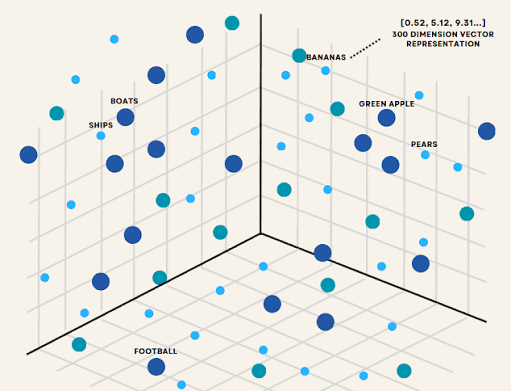

In [15]:
# Step 4 RAG

# User asks a question
# 1) How to build a boat ?

# Phase 1: Retrieval (retrieve relevant chunks from the vector DB)
# 1) boats -> pages
# 2) ships -> pages

# Phase 2: Augmenation (Write a prompt to LLM with the user query + retrieved chunks)

# prompt = f"Given here is the user query:{user_query} and 
# the relevant document chunks: {retrieved_chunks}, 
# please answer the user query based on the document chunks."

# Phase 3: Generation (LLM generates the answer based on the prompt)

# final answer = call_llm(prompt)

https://medium.com/@drjulija/what-is-retrieval-augmented-generation-rag-938e4f6e03d1

## RAG Pipeline

## One time store vector database

In [16]:
!pip install langchain_community langchain langchain_ollama pypdf chromadb -qU


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
!pip install langchain_community langchain langchain_ollama pypdf chromadb langchain_huggingface -qU


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
!pip install faiss-cpu 
!pip install -U langchain-community faiss-cpu


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.9 MB ? eta -:--:--
    --------------------------------------- 0.3/16.9 MB ? eta -:--:--
    --------------------------------------- 0.3/16.9 MB ? eta -:--:--
   - -------------------------------------- 0.8/16.9 MB 1.1 MB/s eta 0:00:16
   -- ------------------------------------- 1.0/16.9 MB 1.1 MB/s eta 0:00:15
   ---- ----------------------------------- 1.8/16.9 MB 1.7 MB/s eta 0:00:09
   ---- ----------------------------------- 2.1/16.9 MB 1.6 MB/s eta 0:00:10
   ------ --------------------------------- 2.6/16.9 MB 1.8 MB/s eta 0:00:08
   ------- -------------------------------- 3.1/16.9 MB


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
%pip install langchain-community faiss-cpu

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import faiss
from langchain_community.vectorstores import FAISS

print("FAISS imported successfully!")

C:\Users\KULPREET SEMBHI\AppData\Local\Temp\ipykernel_3944\1419259874.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


FAISS imported successfully!


In [21]:
import sys

print(sys.executable)
print(sys.version)

c:\Users\KULPREET SEMBHI\AppData\Local\Programs\Python\Python314\python.exe
3.14.0 (tags/v3.14.0:ebf955d, Oct  7 2025, 10:15:03) [MSC v.1944 64 bit (AMD64)]


In [22]:
import os, sys
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import Chroma
# from langchain.prompts import ChatPromptTemplate
from langchain_ollama import OllamaEmbeddings,OllamaLLM
from langchain_huggingface import HuggingFaceEmbeddings

c:\Users\KULPREET SEMBHI\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [23]:
DOC_PATH = "2027-volvo-xc90.pdf"
# CHROMA_PATH = "your_db_name" 

# ----- Data Indexing Process -----

# load your pdf doc
loader = PyPDFLoader(DOC_PATH)
pages = loader.load()

# split the doc into smaller chunks i.e. chunk_size=500
text_splitter = RecursiveCharacterTextSplitter(chunk_size=5000, chunk_overlap=250)
chunks = text_splitter.split_documents(pages)

# get Ollama Embedding model
# embeddings = OllamaEmbeddings(model="nomic-embed-text")
embeddings_model = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")

# embed the chunks as vectors and load them into the database
vectorstore = Chroma.from_documents(chunks, embeddings_model) #, persist_directory=CHROMA_PATH)


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2693.10it/s]


In [24]:
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import Chroma
from langchain_community.vectorstores import FAISS

vectorstore = FAISS.from_documents(chunks,embeddings_model)
vectorstore.save_local("falss_index")

## RAG Phase

In [25]:
llm=OllamaLLM(model="llama3.2")

In [26]:
# ----- Retrieval and Generation Process -----

# this is an example of a user question (query)
query = 'Could you explain in detail about location of ISOFIX child seats'

# retrieve context - top 5 most relevant (closests) chunks to the query vector 
# (by default Langchain is using cosine distance metric)
docs_chroma = vectorstore.similarity_search_with_score(query, k=5)

# generate an answer based on given user query and retrieved context information
context_text = "\n\n".join([doc.page_content for doc, _score in docs_chroma])

# you can use a prompt template
prompt = f"""
Answer the question based only on the following context:
{context_text}
Answer the question based on the above context: {query}.
Provide a detailed answer.
Don’t justify your answers.
Don’t give information not mentioned in the CONTEXT INFORMATION.
Do not say "according to the context" or "mentioned in the context" or similar.
"""

answer = llm.invoke(prompt)
print("Answer:", answer)

Answer: The locations of ISOFIX child seats are between the seat's backrest and the seat cushion. You may need to push down on the seat cushion to fully access them. The ISOFIX anchorage points are located on the outer second row seats. 

For i-Size child seats, the anchorage locations are indicated by the ISOFIX symbol and are approved for i-Size child restraints. 

Table 15.5.11 provides a recommendation for which ISOFIX child seats suit which locations, and for what size of child. The table gives a recommendation for the seven seat variant.

For the seven seat variant, the table provides recommendations for front seats (with deactivated or activated airbag), second row seats (outer or centre seat), and third seat row.

The recommended anchorage locations for ISOFIX child seats on the outer second row seats are for use with ISOFIX child restraints.


In [27]:
print(context_text)

The ISOFIX anchorage points can be used in combination with other fastening methods to secure i-Size and ISOFIX child re-
straints. These anchorage points are part of an international standard for child restraints.
Child restraint installed using ISOFIX
Attaching to ISOFIX anchorage point
Child restraints installed on any of the outer second row seats can use these anchorage points.
Locations of ISOFIX anchorage points for the second row seats
The ISOFIX anchorage points are located between the seat's backrest and the seat cushion. You may need to push down on the
seat cushion to fully access them.
 Note
ISOFIX is an international standard for child restraint anchorage points. It is also known by other regional names such as
LATCH and LUAS.
The content of this manual represents the status of the user manual at the time of printing and may not be completely valid in future
instances. For more information, refer to the first page for the complete disclaimer note.
152 / 443

[1] For child